# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset **tanpa label** dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Sumber Dataset: Kaggle Datasets.
   - Link Dataset: https://www.kaggle.com/datasets/kedokedokedo/vgsales
   - Deskripsi: Dataset ini berisi daftar video game dengan penjualan di seluruh dunia.
   
   Informasi Dataset:
   - Tanpa Label: Dataset ini awalnya tidak memiliki label atau kelas untuk clustering. Anda dapat menggunakannya untuk melakukan unsupervised learning seperti clustering.

3. **Pembatasan**:  
   Dataset ini telah digunakan dalam latihan clustering sebelumnya, terutama untuk segmentasi pelanggan berdasarkan preferensi game. Namun, Anda masih dapat menggunakannya untuk latihan clustering dengan fokus pada aspek lain, seperti pengelompokkan game berdasarkan kesamaan penjualan di berbagai wilayah.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

In [152]:
df = pd.read_csv('/content/vgsales.csv')

df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset. EDA bertujuan untuk:

1. **Memahami Struktur Data**
   - Tinjau jumlah baris dan kolom dalam dataset.  
   - Tinjau jenis data di setiap kolom (numerikal atau kategorikal).

2. **Menangani Data yang Hilang**  
   - Identifikasi dan analisis data yang hilang (*missing values*). Tentukan langkah-langkah yang diperlukan untuk menangani data yang hilang, seperti pengisian atau penghapusan data tersebut.

3. **Analisis Distribusi dan Korelasi**  
   - Analisis distribusi variabel numerik dengan statistik deskriptif dan visualisasi seperti histogram atau boxplot.  
   - Periksa hubungan antara variabel menggunakan matriks korelasi atau scatter plot.

4. **Visualisasi Data**  
   - Buat visualisasi dasar seperti grafik distribusi dan diagram batang untuk variabel kategorikal.  
   - Gunakan heatmap atau pairplot untuk menganalisis korelasi antar variabel.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

## 4.1

In [153]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [154]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


## 4.2

In [155]:
df.isna().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


## 4.3

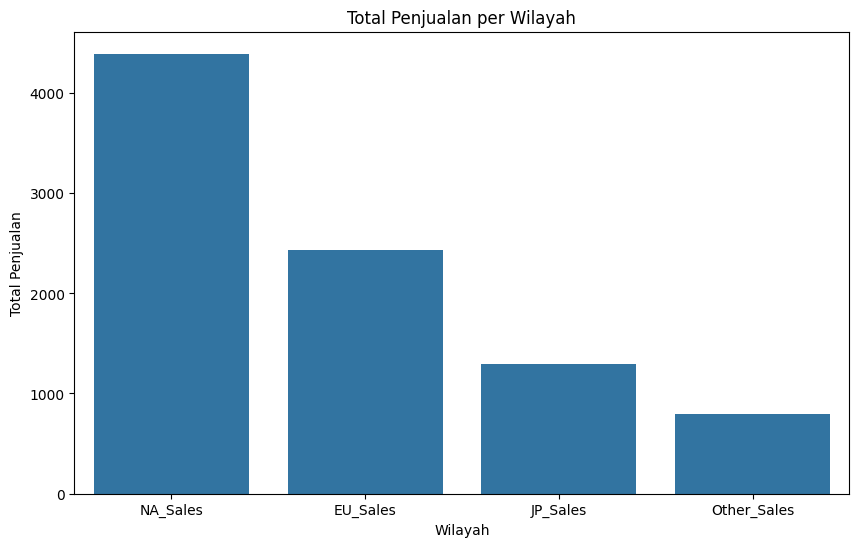

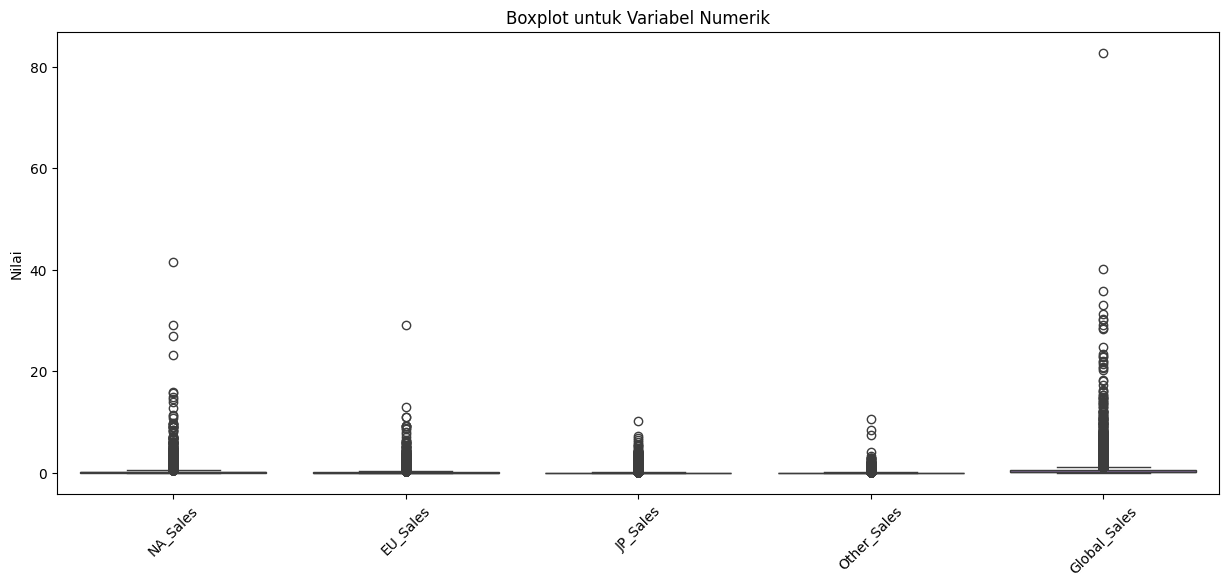

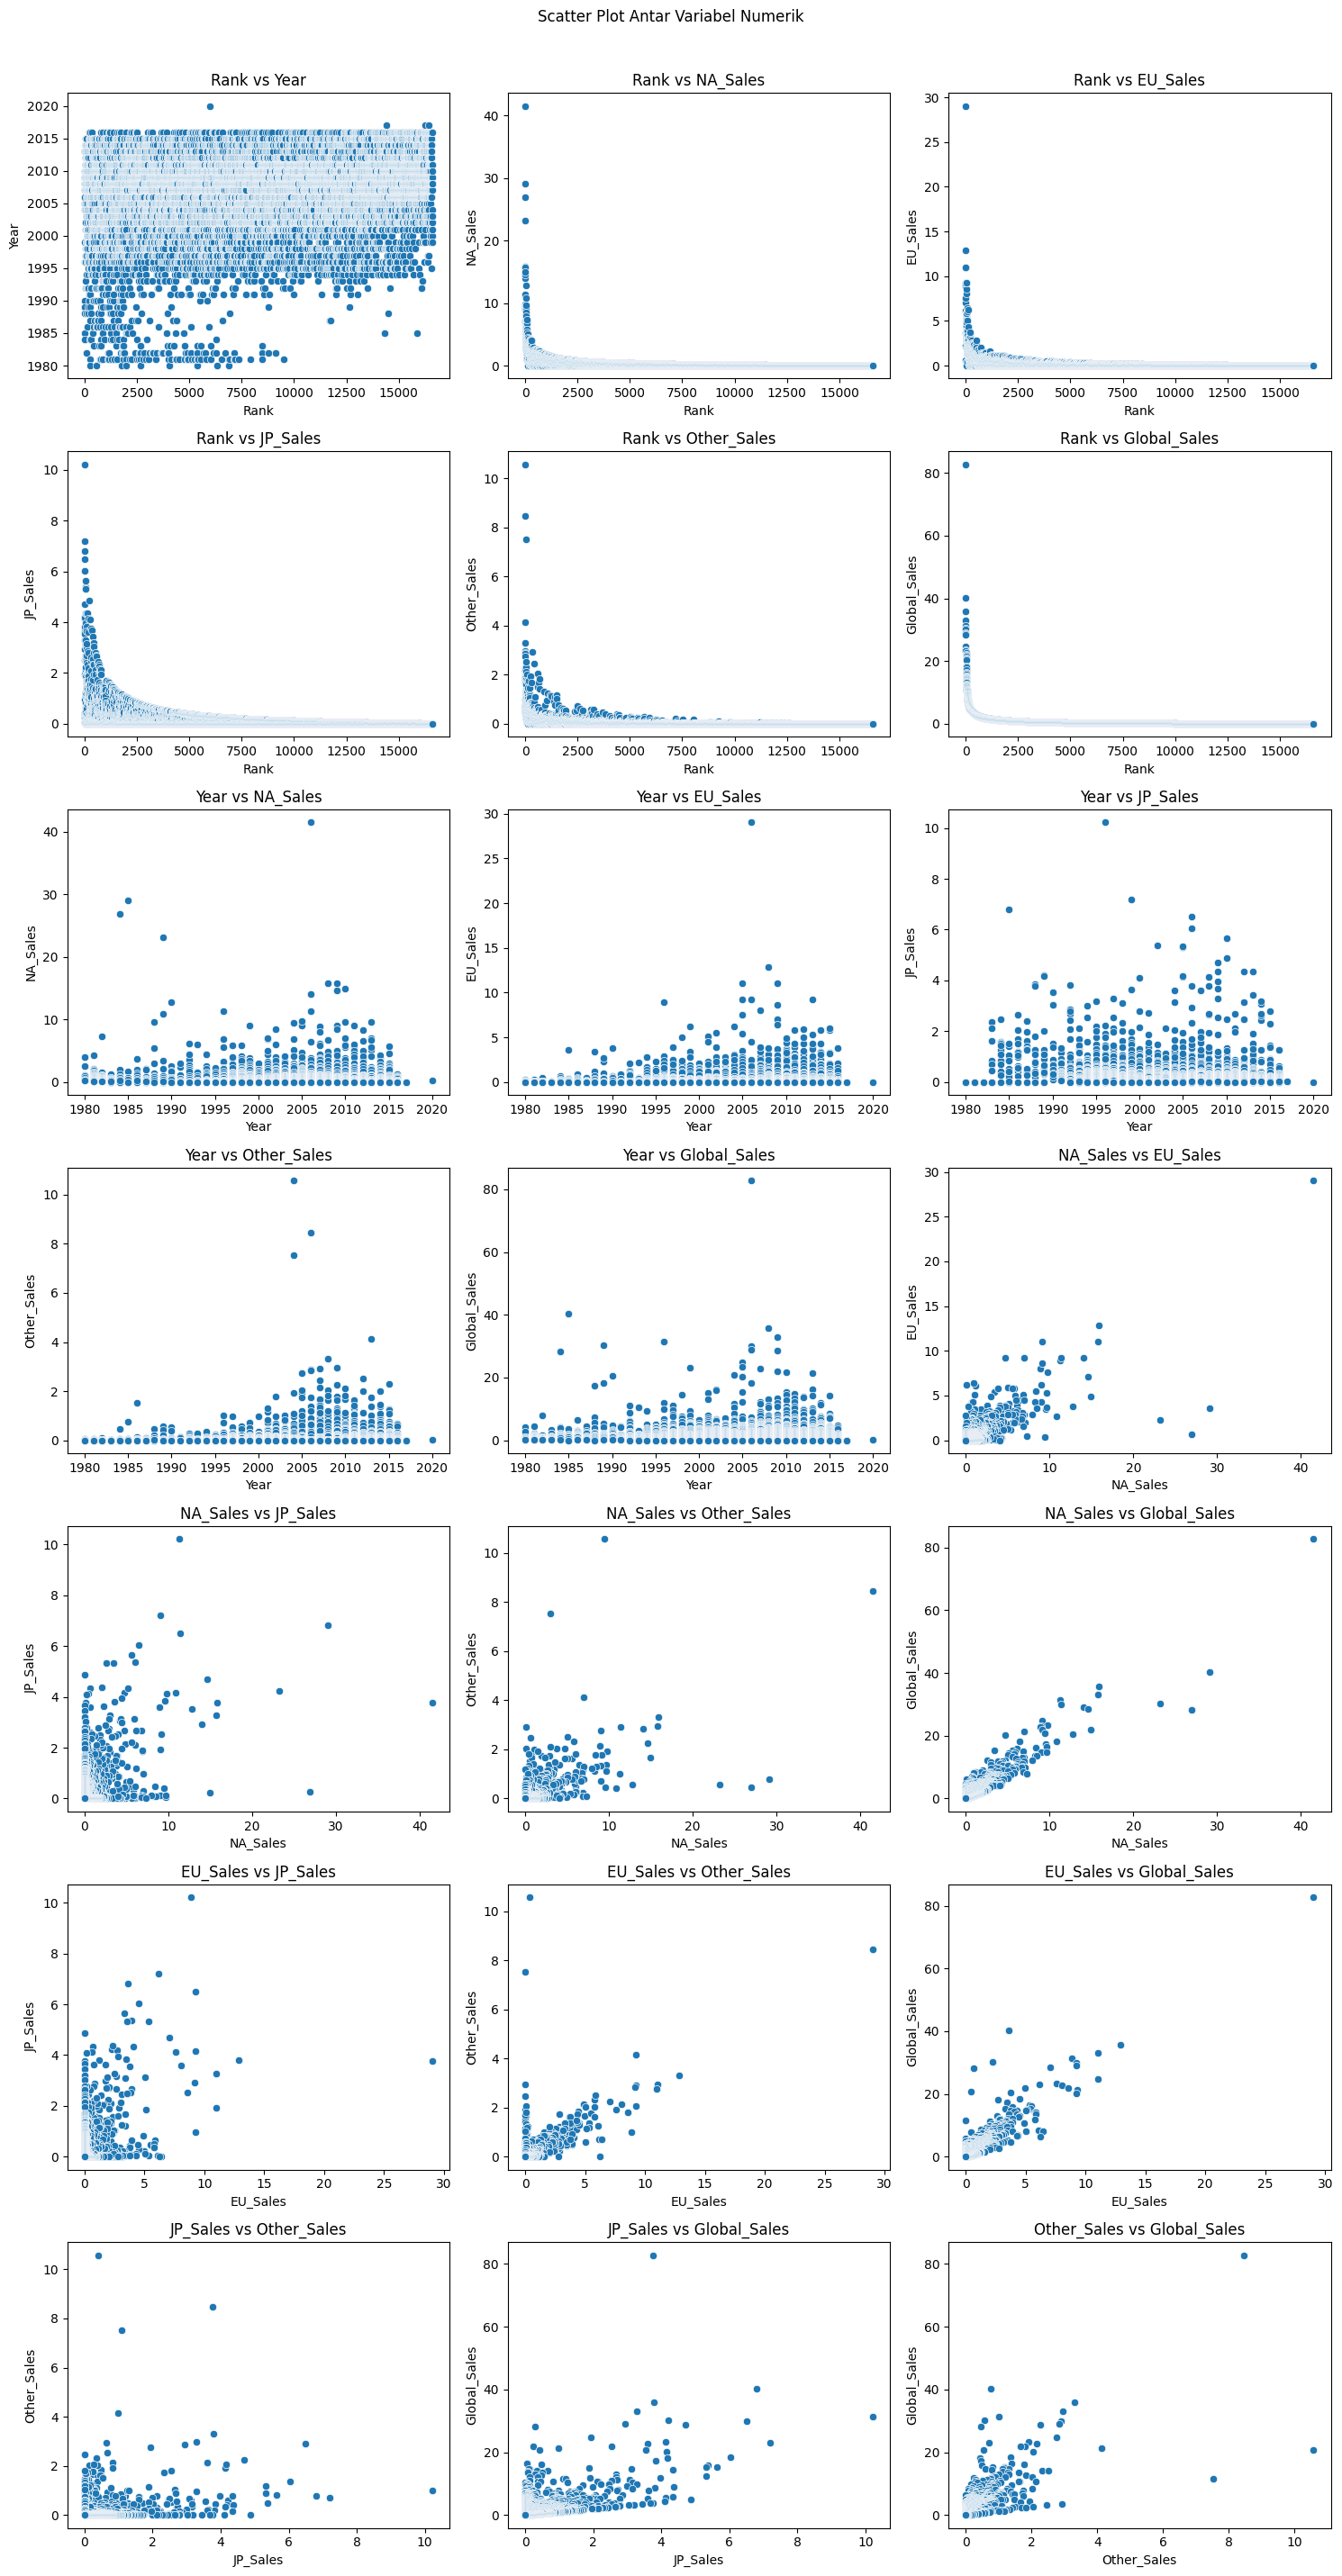

In [156]:
# Mengubah DataFrame untuk visualisasi
sales_data = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]]
sales_data_melted = sales_data.melt(var_name="Region", value_name="Sales")

# Membuat bar chart untuk penjualan
plt.figure(figsize=(10, 6))
sns.barplot(data=sales_data_melted, x="Region", y="Sales", estimator=sum, errorbar=None)
plt.title("Total Penjualan per Wilayah")
plt.xlabel("Wilayah")
plt.ylabel("Total Penjualan")
plt.show()

# Boxplot untuk analisis outlier
numerical_features = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

plt.figure(figsize=(15, 6))
sns.boxplot(data=df[numerical_features])
plt.title("Boxplot untuk Variabel Numerik")
plt.ylabel("Nilai")
plt.xticks(rotation=45)
plt.show()

# Scatter plot antar variabel numerik
combinations = list(itertools.combinations(numerical_df.columns, 2))
n_plots = len(combinations)
n_cols = 3
n_rows = int(np.ceil(n_plots / n_cols))

plt.figure(figsize=(n_cols * 5, n_rows * 4))
for i, (x_var, y_var) in enumerate(combinations):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.scatterplot(data=numerical_df, x=x_var, y=y_var)
    plt.title(f'{x_var} vs {y_var}')
    plt.tight_layout()

plt.suptitle("Scatter Plot Antar Variabel Numerik", y=1.02)
plt.show()


## 4.4

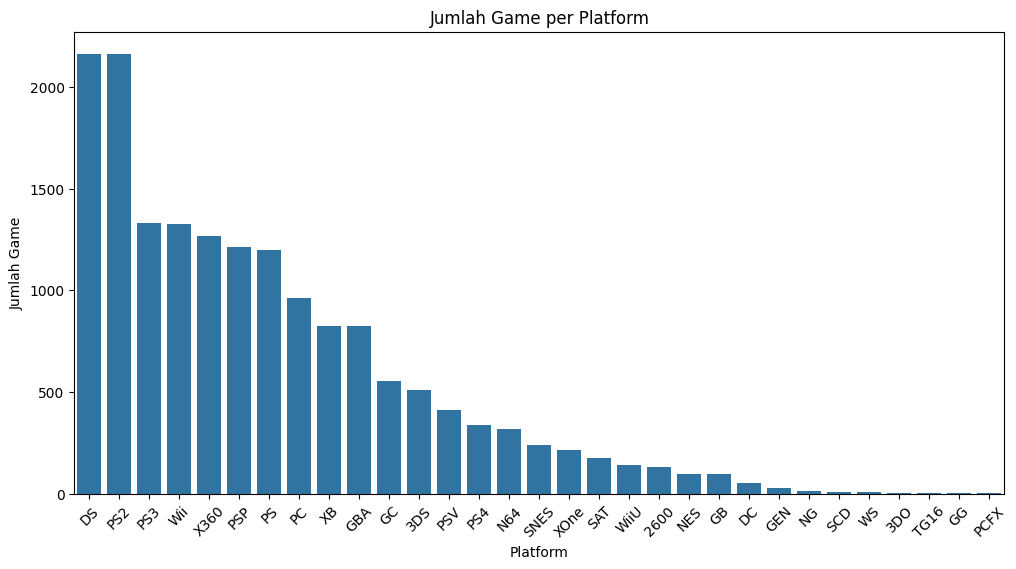

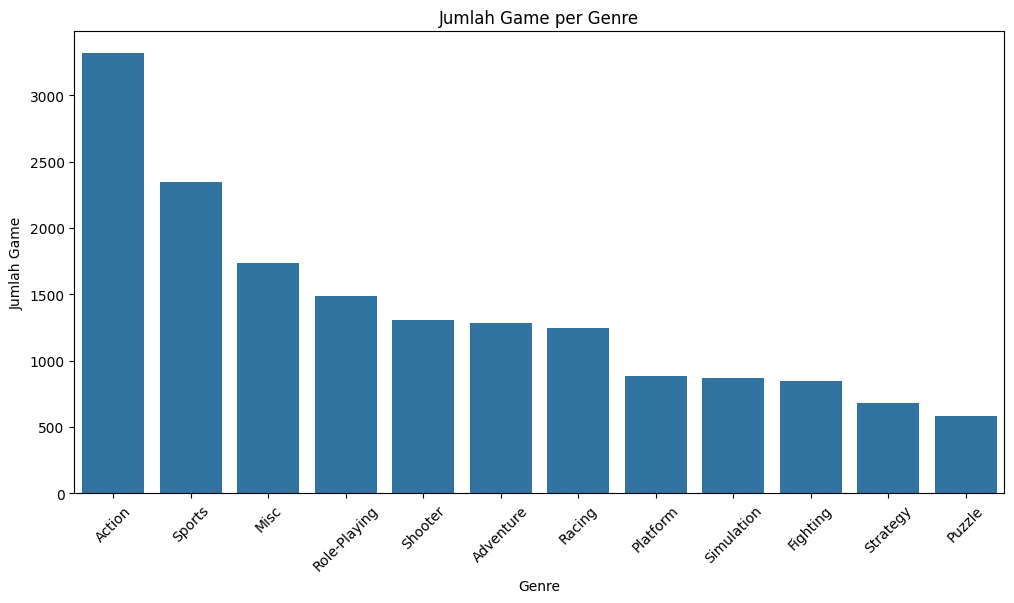

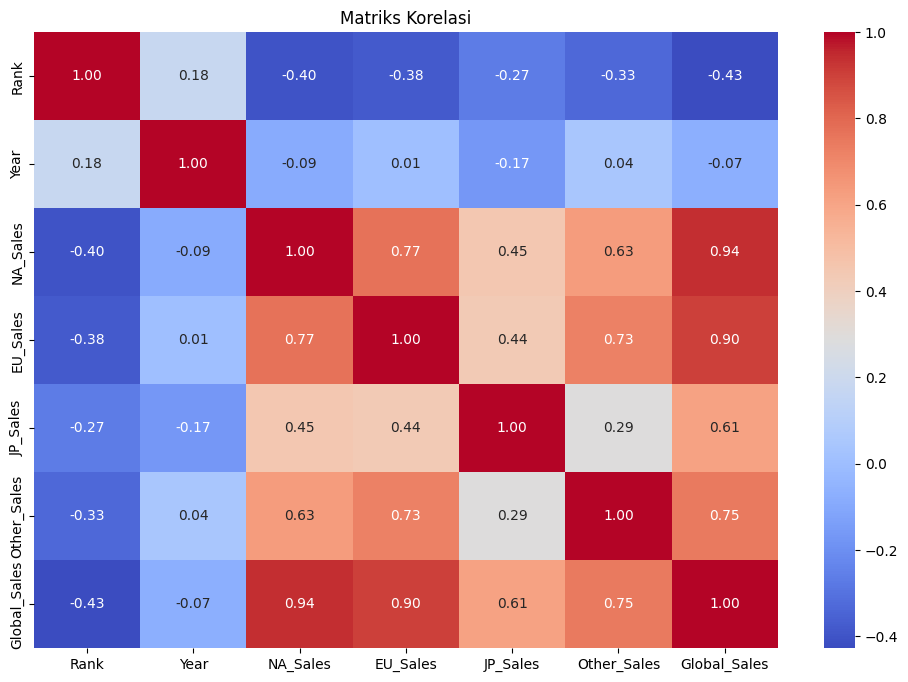

In [157]:
# Visualisasi untuk variabel kategorikal
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="Platform", order=df["Platform"].value_counts().index)
plt.title("Jumlah Game per Platform")
plt.xlabel("Platform")
plt.ylabel("Jumlah Game")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="Genre", order=df["Genre"].value_counts().index)
plt.title("Jumlah Game per Genre")
plt.xlabel("Genre")
plt.ylabel("Jumlah Game")
plt.xticks(rotation=45)
plt.show()

# Visualisasi Korelasi antar Variabel
numerical_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
correlation_matrix = numerical_df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriks Korelasi")
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning. Data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah.

## 5.1  Menghapus atau Menangani Data Kosong (Missing Values)

In [158]:
df = df.drop(columns=["Year", "Publisher"])

In [159]:
df.dropna(inplace=True)

In [160]:
df.isna().sum()

,0
Rank,0
Name,0
Platform,0
Genre,0
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0
Global_Sales,0


## 5.2 Menghapus Data Duplikat

In [161]:
df.duplicated().sum()

np.int64(0)

In [162]:
df["Total Sales"] = (
    df["NA_Sales"]
    + df["EU_Sales"]
    + df["JP_Sales"]
    + df["Other_Sales"]
    + df["Global_Sales"]
)

df.head()

,Rank,Name,Platform,Genre,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Total Sales
0,1,Wii Sports,Wii,Sports,41.49,29.02,3.77,8.46,82.74,165.48
1,2,Super Mario Bros.,NES,Platform,29.08,3.58,6.81,0.77,40.24,80.48
2,3,Mario Kart Wii,Wii,Racing,15.85,12.88,3.79,3.31,35.82,71.65
3,4,Wii Sports Resort,Wii,Sports,15.75,11.01,3.28,2.96,33.00,66.00
4,5,Pokemon Red/Pokemon Blue,GB,Role-Playing,11.27,8.89,10.22,1.00,31.37,62.75


##5.3 Normalisasi atau Standarisasi Fitur

In [163]:
# Pilih fitur numerikal dan kategorikal
numerical_features = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Total Sales']
categorical_features = ['Genre', 'Platform']


scaler = StandardScaler()

# Transform fitur numerik
df_numeric_scaled = pd.DataFrame(scaler.fit_transform(df[numerical_features]),
                                 columns=numerical_features,
                                 index=df.index)

##5.4 Deteksi dan Penanganan Outlier

In [164]:
Q1 = df_numeric_scaled.quantile(0.25)
Q3 = df_numeric_scaled.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter outlier pada DataFrame asli sebelum scaling
df_no_outliers = df_numeric_scaled[~((df_numeric_scaled < lower_bound) | (df_numeric_scaled > upper_bound)).any(axis=1)]

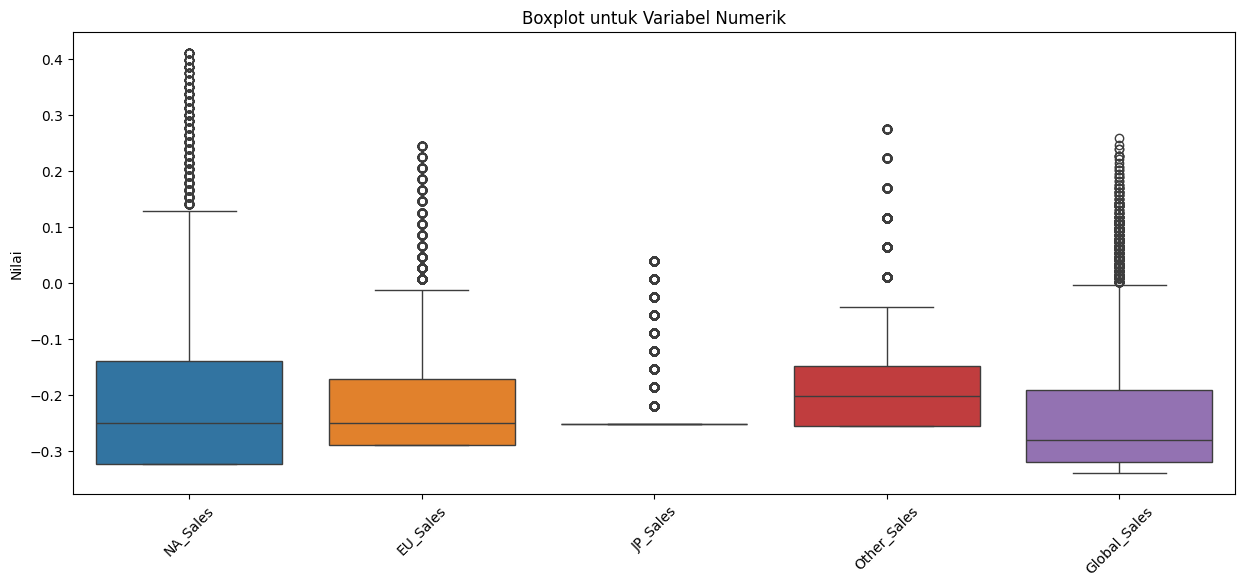

In [165]:
numerical_features = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

plt.figure(figsize=(15, 6))
sns.boxplot(data=df_no_outliers[numerical_features])
plt.title("Boxplot untuk Variabel Numerik")
plt.ylabel("Nilai")
plt.xticks(rotation=45)
plt.show()

##5.5 Encoding Data Kategorikal

In [166]:
# Preprocessing: Standarisasi numerik & One-Hot Encoding kategorikal
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Transform fitur kategorikal
X_categorical_encoded = encoder.fit_transform(df[categorical_features])

##5.6 Binning

In [167]:
# Gabungkan semua fitur
X_preprocessed = np.hstack((df_numeric_scaled, X_categorical_encoded)) # Gunakan df_numeric_scaled

# **6. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan. Berikut adalah **rekomendasi** tahapannya.
1. Pilih algoritma clustering yang sesuai.
2. Latih model dengan data menggunakan algoritma tersebut.

In [168]:
# Menentukan rentang jumlah cluster yang akan diuji
k_range = range(2, 11)
inertia = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_preprocessed)
    inertia.append(kmeans.inertia_)

## **b. Evaluasi Model Clustering**

Untuk menentukan jumlah cluster yang optimal dalam model clustering, Anda dapat menggunakan metode Elbow atau Silhouette Score.

Metode ini membantu kita menemukan jumlah cluster yang memberikan pemisahan terbaik antar kelompok data, sehingga model yang dibangun dapat lebih efektif. Berikut adalah **rekomendasi** tahapannya.
1. Gunakan Silhouette Score dan Elbow Method untuk menentukan jumlah cluster optimal.
2. Hitung Silhouette Score sebagai ukuran kualitas cluster.

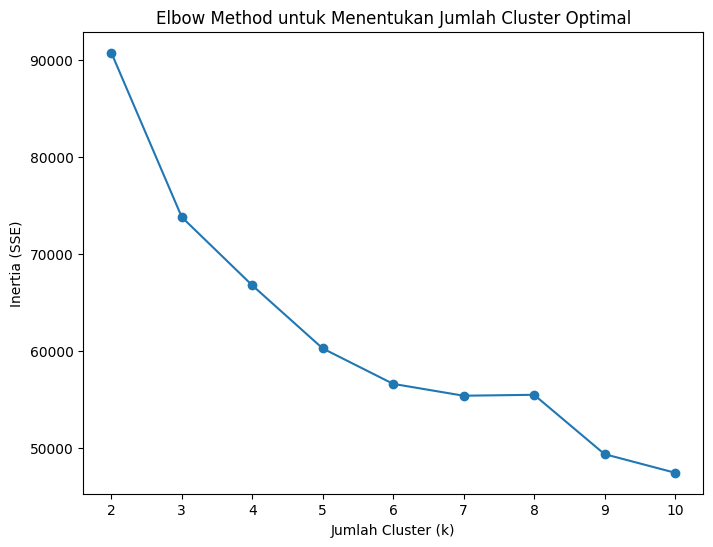

Jumlah cluster optimal berdasarkan Silhouette Score: 2


In [169]:
plt.figure(figsize=(8, 6))
plt.plot(k_range, inertia, marker='o')
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia (SSE)")
plt.title("Elbow Method untuk Menentukan Jumlah Cluster Optimal")
plt.show()

optimal_k = k_range[np.argmax(silhouette_scores)]
print(f"Jumlah cluster optimal berdasarkan Silhouette Score: {optimal_k}")

In [170]:
silhouette_scores = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X_preprocessed)
    silhouette_avg = silhouette_score(X_preprocessed, cluster_labels)
    silhouette_scores.append(silhouette_avg)

best_k = k_range[np.argmax(silhouette_scores)]  # Menyimpan jumlah cluster optimal
best_score = np.max(silhouette_scores)       # Menyimpan Silhouette Score terbaik

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_preprocessed)

print(f"Jumlah cluster optimal: {best_k}")
print(f"Silhouette Score: {best_score:.4f}")

Jumlah cluster optimal: 2
Silhouette Score: 0.8875


## **c. Feature Selection (Opsional)**

Silakan lakukan feature selection jika Anda membutuhkan optimasi model clustering. Jika Anda menerapkan proses ini, silakan lakukan pemodelan dan evaluasi kembali menggunakan kolom-kolom hasil feature selection. Terakhir, bandingkan hasil performa model sebelum dan sesudah menerapkan feature selection.

## **d. Visualisasi Hasil Clustering**

Setelah model clustering dilatih dan jumlah cluster optimal ditentukan, langkah selanjutnya adalah menampilkan hasil clustering melalui visualisasi.

Berikut adalah **rekomendasi** tahapannya.
1. Tampilkan hasil clustering dalam bentuk visualisasi, seperti grafik scatter plot atau 2D PCA projection.

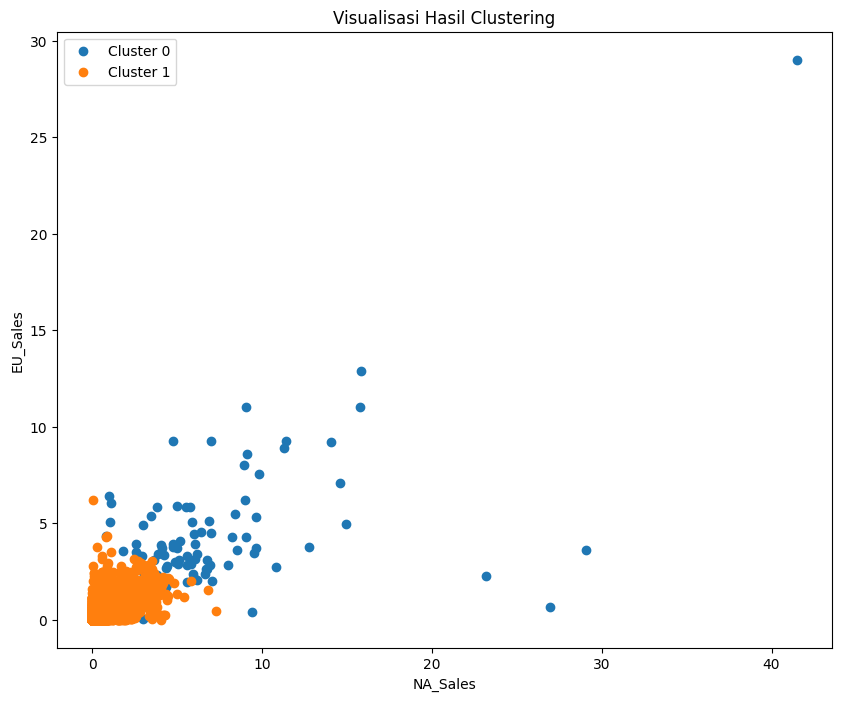

In [171]:
feature1 = 'NA_Sales'
feature2 = 'EU_Sales'

plt.figure(figsize=(10, 8))
for cluster_label in df['Cluster'].unique():
    cluster_data = df[df['Cluster'] == cluster_label]
    plt.scatter(cluster_data[feature1], cluster_data[feature2], label=f'Cluster {cluster_label}')

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title('Visualisasi Hasil Clustering')
plt.legend()
plt.show()

## **e. Analisis dan Interpretasi Hasil Cluster**

### Interpretasi Target

**Tutorial: Melakukan Inverse Transform pada Data Target Setelah Clustering**

Setelah melakukan clustering dengan model **KMeans**, kita perlu mengembalikan data yang telah diubah (normalisasi, standarisasi, atau label encoding) ke bentuk aslinya. Berikut adalah langkah-langkahnya.

---

**1. Tambahkan Hasil Label Cluster ke DataFrame**
Setelah mendapatkan hasil clustering, kita tambahkan label cluster ke dalam DataFrame yang telah dinormalisasi.

```python
df_normalized['Cluster'] = model_kmeans.labels_
```

Lakukan Inverse Transform pada feature yang sudah dilakukan Labelisasi dan Standararisasi. Berikut code untuk melakukannya:
label_encoder.inverse_transform(X_Selected[['Fitur']])

Lalu masukkan ke dalam kolom dataset asli atau membuat dataframe baru
```python
df_normalized['Fitur'] = label_encoder.inverse_transform(df_normalized[['Fitur']])
```
Masukkan Data yang Sudah Di-Inverse ke dalam Dataset Asli atau Buat DataFrame Baru
```python
df_original['Fitur'] = df_normalized['Fitur']
```

In [172]:
# Inverse transform untuk fitur kategorikal
decoded_categories = encoder.inverse_transform(X_categorical_encoded)
df[categorical_features] = decoded_categories

# Tampilkan beberapa hasil clustering
display(df[['Genre', 'Platform', 'Cluster']].head(10))

,Genre,Platform,Cluster
0,Sports,Wii,0
1,Platform,NES,0
2,Racing,Wii,0
3,Sports,Wii,0
4,Role-Playing,GB,0
5,Puzzle,GB,0
6,Platform,DS,0
7,Misc,Wii,0
8,Platform,Wii,0
9,Shooter,NES,0


In [173]:
df.head()

,Rank,Name,Platform,Genre,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Total Sales,Cluster
0,1,Wii Sports,Wii,Sports,41.49,29.02,3.77,8.46,82.74,165.48,0
1,2,Super Mario Bros.,NES,Platform,29.08,3.58,6.81,0.77,40.24,80.48,0
2,3,Mario Kart Wii,Wii,Racing,15.85,12.88,3.79,3.31,35.82,71.65,0
3,4,Wii Sports Resort,Wii,Sports,15.75,11.01,3.28,2.96,33.00,66.00,0
4,5,Pokemon Red/Pokemon Blue,GB,Role-Playing,11.27,8.89,10.22,1.00,31.37,62.75,0


### Inverse Data Jika Melakukan Normalisasi/Standardisasi

Inverse Transform untuk Data yang Distandarisasi
Jika data numerik telah dinormalisasi menggunakan StandardScaler atau MinMaxScaler, kita bisa mengembalikannya ke skala asli:
```python
df_normalized[['Fitur_Numerik']] = scaler.inverse_transform(df_normalized[['Fitur_Numerik']])
```

In [174]:
# Ensure numerical_features has the correct columns to update
numerical_features = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales", "Total Sales"]

# Inverse transform for numerical features (unchanged from previous fix)
X_numeric_decoded = scaler.inverse_transform(df_numeric_scaled)
df_numeric_decoded = pd.DataFrame(X_numeric_decoded, columns=numerical_features, index=df.index)

# Update the original DataFrame (unchanged from previous fix)
df[numerical_features] = df_numeric_decoded[numerical_features]

# Tampilkan beberapa hasil clustering (unchanged from previous fix)
print(df[numerical_features + ['Genre', 'Platform', 'Cluster']].head(10))

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  Total Sales  \
0     41.49     29.02      3.77         8.46         82.74       165.48   
1     29.08      3.58      6.81         0.77         40.24        80.48   
2     15.85     12.88      3.79         3.31         35.82        71.65   
3     15.75     11.01      3.28         2.96         33.00        66.00   
4     11.27      8.89     10.22         1.00         31.37        62.75   
5     23.20      2.26      4.22         0.58         30.26        60.52   
6     11.38      9.23      6.50         2.90         30.01        60.02   
7     14.03      9.20      2.93         2.85         29.02        58.03   
8     14.59      7.06      4.70         2.26         28.62        57.23   
9     26.93      0.63      0.28         0.47         28.31        56.62   

          Genre Platform  Cluster  
0        Sports      Wii        0  
1      Platform      NES        0  
2        Racing      Wii        0  
3        Sports      Wii      

Setelah melakukan clustering, langkah selanjutnya adalah menganalisis karakteristik dari masing-masing cluster berdasarkan fitur yang tersedia.

Berikut adalah **rekomendasi** tahapannya.
1. Analisis karakteristik tiap cluster berdasarkan fitur yang tersedia (misalnya, distribusi nilai dalam cluster).
2. Berikan interpretasi: Apakah hasil clustering sesuai dengan ekspektasi dan logika bisnis? Apakah ada pola tertentu yang bisa dimanfaatkan?

In [175]:
df_cluster_summary = df.groupby('Cluster')[numerical_features].mean()
print(df_cluster_summary)

for feature in categorical_features:
    print(df.groupby('Cluster')[feature].value_counts())

         NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  Total Sales
Cluster                                                                      
0        7.213736  4.482967  2.171319     1.429451     15.296703    30.594176
1        0.226359  0.122747  0.066240     0.040448      0.456076     0.911869
Cluster  Genre       
0        Shooter           18
         Role-Playing      15
         Platform          13
         Action            11
         Racing            10
         Misc               9
         Sports             7
         Simulation         4
         Puzzle             2
         Adventure          1
         Fighting           1
1        Action          3305
         Sports          2339
         Misc            1730
         Role-Playing    1473
         Shooter         1292
         Adventure       1285
         Racing          1239
         Platform         873
         Simulation       863
         Fighting         847
         Strategy         681
      

<Axes: xlabel='Cluster', ylabel='NA_Sales'>

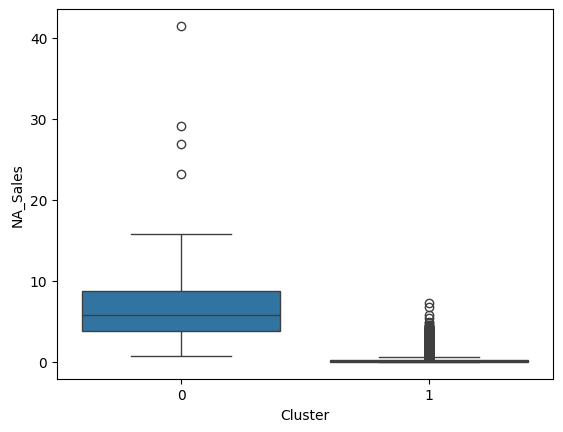

In [176]:
sns.boxplot(x='Cluster', y='NA_Sales', data=df)

Tulis hasil interpretasinya di sini.
1. Cluster 1:
2. Cluster 2:
3. Cluster 3:

## Analisis Karakteristik Cluster dari Model KMeans

Berikut adalah analisis karakteristik untuk setiap cluster yang dihasilkan dari model KMeans berdasarkan genre dan platform dari dataset video game.

### Cluster 0

Dominan Genre:
- Shooter: 18
- Role-Playing: 15
- Platform: 13
- Action: 11
- Racing: 10

Dominan Platform:
- Wii: 14
- X360: 14
- DS: 13
- PS3: 11

Analisis:
Cluster ini mencerminkan kelompok game yang tersebar di berbagai genre populer, tapi dalam jumlah yang relatif kecil. Genre seperti Shooter, RPG, dan Platformer muncul cukup seimbang. Platform yang mendominasi di cluster ini adalah konsol generasi ketujuh dan sebelumnya, seperti Wii, Xbox 360, DS, dan PS3.

Hal ini bisa menunjukkan bahwa cluster ini berisi game-game yang lebih niche atau klasik. Mereka mungkin punya nilai historis atau nostalgia tinggi, tapi tidak mendominasi pasar secara keseluruhan. Cocok untuk game dengan komunitas kecil namun loyal.

---

### Cluster 1

Dominan Genre:
- Action: 3298
- Sports: 2334
- Misc: 1703
- Role-Playing: 1471
- Shooter: 1290
- Adventure: 1281

Dominan Platform:
- PS2: 2153
- DS: 2143
- PS3: 1315
- Wii: 1310
- X360: 1247

Analisis:
Cluster ini adalah representasi dari arus utama industri game. Genre seperti Action dan Sports sangat dominan, menunjukkan bahwa game-game di sini adalah game dengan target pasar luas dan jumlah rilis tinggi.

Platform-platform yang dominan juga berasal dari era kejayaan PS2, DS, PS3, dan Xbox 360, menunjukkan bahwa cluster ini sangat terkait dengan masa keemasan industri game di awal 2000-an hingga pertengahan 2010-an.

Kesimpulannya, cluster ini bisa dianggap sebagai kelompok game-game "blockbuster" atau AAA — game yang secara komersial sukses, banyak dikenal, dan mendefinisikan tren industri di masanya.


# **7. Mengeksport Data**

Simpan hasilnya ke dalam file CSV.

In [177]:
df.to_csv('/content/vgsales_clustered.csv', index=False)